# Supplementary Note 2 · The energy-system configuration

What the residual load is computed against: the capacity the scenario installs, the demand it has to
serve, and how the two dispatchable assets — reservoir hydro and batteries — are operated.

Artwork rules and the caption/height rule are those of Note 1. Numbering continues: **Note 2 is
S17–S22**.

| | content | figures |
|---|---|---|
| **S17** | what TYNDP LOW/2050 installs, by country and by zone | 1 |
| **S18** | LOW against HIGH, and where the extra capacity lands | 1 |
| **S19** | the DE/2050 baseload the build-out has to serve | 1 |
| **S20** | reservoir dispatch over the year | 1 |
| **S21** | reservoir storage over the year | 1 |
| **S22** | battery throughput | 1 |

In [ ]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.collections import LineCollection

from cordex2energy.conversion_energy.tyndp import (
    REALTIME_BALANCING_ZONES,
    load_tyndp_battery_capacities,
    load_tyndp_supply_capacities,
)
from cordex2energy_analysis.analysis import compute_sign_agreement, load_warming_level_periods
from cordex2energy_analysis.extremes_analysis import (
    compute_annual_operation_curves,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.figure_cache import cached
from cordex2energy_analysis.plotting_paper import MAP_CRS, PaperStyle, load_country_geometry
from cordex2energy_analysis.plotting_publication import (
    FS,
    GWL_TITLE,
    SCENARIO_COLORS,
    MM, WIDTH,
    MapRow,
    fit_width,
    gcm_warming_figure,
    gwl_handles,
    gwl_maps,
    legend_below,
    model_characterisation_figure,
    panel_letters,
    publication_rc,
    sign_agreement,
    save,
)
from cordex2energy_analysis.plotting_si import TECH_COLORS, ZONE_COLORS

In [3]:
# ── Configuration. The ANALYSIS settings are the paper's, verbatim. ─────────────────────
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_EXTREMES = PATH_PROCESSED / "extremes"
PATH_GWL = PATH_PROCESSED / "energy" / "analysis"
PATH_RESIDUAL_LOAD = PATH_EXTREMES / "residual_load"
FIGS = Path(paths.get("path_figs", "../figs")) / "si_note2_system"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
RUN_TAG = "DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
WARMING_LEVELS = [1.5, 2.0, 3.0]
ROBUSTNESS_FRACTION = 2 / 3
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]

# The TYNDP scenario the whole paper runs on, and the one Figure 8 tests it against (S12).
SUPPLY_SCENARIO, SUPPLY_YEAR = "LOW", 2050
COMPARISON_SCENARIO = "HIGH"        # same target year: what differs is the ambition, not the date
DEMAND_SCENARIO, DEMAND_YEAR = "DE", 2050

ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberia", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]

_main = json.load(open("paper_figures_publication.ipynb"))
_tags = {line.split('"')[1] for cell in _main["cells"] if cell["cell_type"] == "code"
         for line in cell["source"] if line.startswith("RUN_TAG =")}
assert _tags == {RUN_TAG}, f"run tag drifted from the main figures: {_tags} vs {RUN_TAG}"
print("run tag matches paper_figures_publication.ipynb")
print("figures ->", FIGS)

run tag matches paper_figures_publication.ipynb
figures -> /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/si_note2_system


In [4]:
# ── The chains, their GWL windows, and the PaperStyle every figure is drawn with ────────
models = sorted("_".join(p.name.split("_")[:-1])
                for p in PATH_RESIDUAL_LOAD.glob(f"*_{CLIMATE_SCENARIO}")
                if (p / RUN_TAG).exists())

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

STYLE = PaperStyle(
    zones=ZONE_ORDER, zone_labels=ZONE_LABELS, period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)), driver_palette={}, duration_palette={},
    season_order=SEASON_ORDER, n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD, spread="iqr")

# ETRS89-LAEA (EPSG:3035), the EU's equal-area projection: drawn areas are true areas. The earlier
# lon/lat maps were stretched to their panel box and inflated the north.
countries = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson", crs=MAP_CRS)
# Simplified geometry, as in Figures 2 and 3: at ~55 mm per map a 0.02 deg displacement is ~0.02 mm, an
# order of magnitude below print resolution, and it halves the vector file. The gridded figures
# draw only country BOUNDARIES, so they use it too.
countries_print = countries.copy()
countries_print["geometry"] = countries.geometry.simplify(2000.0)   # metres, ~0.02 deg
assert set(countries_print["ISO2"]) == set(countries["ISO2"]), "simplification dropped a country"

# analysis.compute_sign_agreement goes through apply_ufunc(vectorize=True), i.e. a Python loop over
# every grid cell: 7 s per 426x510 field, 84 s per six-row figure. Assert the fast one agrees
# exactly rather than trusting the swap.
_probe = xr.DataArray(np.random.RandomState(0).randn(len(models), 40, 50),
                      dims=("model", "lat", "lon")).where(
                          np.random.RandomState(1).rand(len(models), 40, 50) > 0.15)
assert (compute_sign_agreement(_probe, model_dim="model").values
        == sign_agreement(_probe).values).all(), "the fast sign agreement is not the reference one"

print(f"{len(models)} chains | robustness {ROBUSTNESS_THRESHOLD}/{len(models)} "
      f"| periods {period_names}")

9 chains | robustness 6/9 | periods ['+1.5°C', '+2.0°C', '+3.0°C']


## 1 · S17: what the scenario installs

> **Supplementary Figure 17 | The TYNDP-2024 LOW/2050 build-out.** **a**, Installed generation
> capacity by country and technology. **b**, Battery energy capacity by country. **c**, **d**, The
> same two quantities summed into the six balancing zones the paper analyses; the zonal panels carry
> no separate key, being the panels above them regrouped in the same colours. Countries outside the
> six zones are omitted, and the zonal totals are asserted equal to the country totals they are
> built from.

In [6]:
# ── What the scenario installs, and the typical-year demand it implies ──────────────────
path_supply_excel = (PATH_EXTREMES / "tyndp"
                     / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx")
solar, wind_onshore, wind_offshore = load_tyndp_supply_capacities(path_supply_excel)

GENERATION_TECHS = ["solar PV", "wind onshore", "wind offshore"]
BATTERY_TECHS = ["battery (prosumer)", "battery (utility)"]

# Only the countries the paper actually models, and the zone each one sits in.
modelled = sorted({c for members in REALTIME_BALANCING_ZONES.values() for c in members})
COUNTRY_ZONE = {c: zone for zone, members in REALTIME_BALANCING_ZONES.items() for c in members}


def capacities_per_country(scenario):
    """Installed capacity by modelled country: GW for generation, GWh for storage.

    One function for both build-outs, so LOW and HIGH are read through the same node->ISO2
    aggregation and the same `{year}_{scenario}` column. When the two were loaded by separate code
    paths there was nothing stopping one of them from reading the wrong column.
    """
    column = f"{SUPPLY_YEAR}_{scenario}"

    def to_iso2(frame):
        nodes = frame[frame["Country"].astype(str).str.len() >= 2].copy()
        nodes["ISO2"] = nodes["Country"].astype(str).str[:2]
        return nodes.groupby("ISO2")[column].sum() / 1000.0

    prosumer, utility = load_tyndp_battery_capacities(
        path_supply_excel, scenario=scenario, year=SUPPLY_YEAR, return_separate=True)
    frame = pd.DataFrame({"solar PV": to_iso2(solar), "wind onshore": to_iso2(wind_onshore),
                          "wind offshore": to_iso2(wind_offshore),
                          "battery (prosumer)": prosumer, "battery (utility)": utility})
    return frame.reindex(modelled).fillna(0.0)


by_country = {scenario: capacities_per_country(scenario)
              for scenario in (SUPPLY_SCENARIO, COMPARISON_SCENARIO)}
generation_gw = by_country[SUPPLY_SCENARIO][GENERATION_TECHS]
battery_gwh = by_country[SUPPLY_SCENARIO][BATTERY_TECHS]


def by_zone(frame):
    """Country rows -> the six balancing zones, in the paper's zone order (not sorted by size).

    Every other zonal panel in the paper is drawn in ZONE_ORDER, so sorting these by capacity would
    make S11c/S11d the only panels a reader has to re-orient to.
    """
    zoned = frame.groupby(frame.index.map(COUNTRY_ZONE)).sum()
    return zoned.reindex(ZONE_ORDER).fillna(0.0)


zonal_gw, zonal_gwh = by_zone(generation_gw), by_zone(battery_gwh)

baseload = xr.open_dataset(
    PATH_EXTREMES / "tyndp" / "baseload" / f"baseload_{DEMAND_SCENARIO}_{DEMAND_YEAR}.nc")["baseload"]

print(f"Generation (GW), {SUPPLY_YEAR}_{SUPPLY_SCENARIO}, by zone:")
print(zonal_gw.round(1).to_string())
print(f"\nBattery (GWh), {SUPPLY_YEAR}_{SUPPLY_SCENARIO}, by zone:")
print(zonal_gwh.round(1).to_string())
print(f"\nBaseload {DEMAND_SCENARIO}/{DEMAND_YEAR}: {baseload.sizes}")

# ── The HIGH/2050 comparison Figure 8 rests on ──────────────────────────────────────────
# S12's caption quotes these totals; they are computed here so the main text never has to state a
# capacity the SI does not show.
scenario_totals = pd.DataFrame({f"{scenario} / {SUPPLY_YEAR}": frame.sum()
                                for scenario, frame in by_country.items()})
scenario_totals["change %"] = (scenario_totals.iloc[:, 1] / scenario_totals.iloc[:, 0] - 1) * 100

# Per zone per technology: how much capacity HIGH adds, and where it lands. The percentage is
# guarded against zones with none of a technology to begin with (no offshore wind inland), where
# the ratio is undefined rather than infinite.
zonal_low, zonal_high = by_zone(by_country[SUPPLY_SCENARIO]), by_zone(by_country[COMPARISON_SCENARIO])
zonal_added = zonal_high - zonal_low
zonal_added_pct = (zonal_high / zonal_low.replace(0.0, np.nan) - 1) * 100

print(f"\nLOW/{SUPPLY_YEAR} against {COMPARISON_SCENARIO}/{SUPPLY_YEAR}, modelled countries "
      f"(GW for generation, GWh for storage):")
print(scenario_totals.round(1).to_string())
print(f"\nCapacity {COMPARISON_SCENARIO} adds over {SUPPLY_SCENARIO}, by zone:")
print(zonal_added.round(1).to_string())

# The three views of the LOW build-out — per country, per zone, and the Europe-wide total — are the
# same numbers summed differently. If any pair disagrees, one of the three is wrong.
assert set(modelled) <= set(COUNTRY_ZONE), \
    f"modelled countries outside the zone map: {sorted(set(modelled) - set(COUNTRY_ZONE))}"
for _name in GENERATION_TECHS + BATTERY_TECHS:
    _country = float(by_country[SUPPLY_SCENARIO][_name].sum())
    assert np.isclose(_country, float(zonal_low[_name].sum())), f"{_name}: zonal sum != country sum"
    assert np.isclose(_country, scenario_totals.loc[_name, f"{SUPPLY_SCENARIO} / {SUPPLY_YEAR}"]), \
        f"{_name}: the Europe-wide total is not the country sum"
assert (scenario_totals["change %"] > 0).all(), \
    f"HIGH is no longer larger in every technology:\n{scenario_totals.round(1)}"
assert (zonal_added.sum(axis=1) > 0).all(), "a zone gains no capacity at all under HIGH"


Generation (GW), 2050_LOW, by zone:
                   solar PV  wind onshore  wind offshore
Iberian_Peninsula     114.8          85.9           12.8
South_East            140.1          43.6           39.0
Central_Western       635.3         228.1          195.8
Central_Eastern        74.2          30.4           34.0
Nordic                 33.0          42.1           89.9
British_Isles          34.5          31.8          114.1

Battery (GWh), 2050_LOW, by zone:
                   battery (prosumer)  battery (utility)
Iberian_Peninsula                 3.2               35.3
South_East                       35.5              209.0
Central_Western                 351.6              208.5
Central_Eastern                   3.6               19.7
Nordic                           10.8                7.6
British_Isles                    91.1               65.0

Baseload DE/2050: Frozen({'hour_of_year': 8760, 'country': 35})

LOW/2050 against HIGH/2050, modelled countries (GW for generation

  S17_tyndp_low_capacities     179.8 x 153.4 mm   panel 33.3 mm   pdf 69 kB  png 310 kB


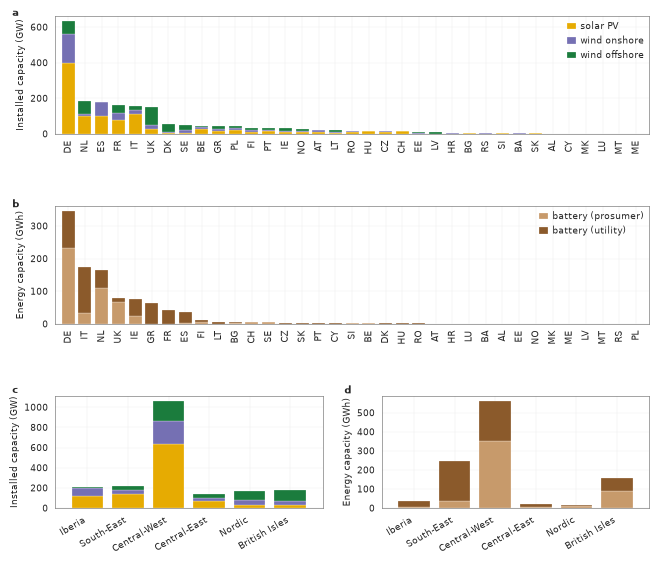

In [7]:
def stacked_capacity(ax, frame, ylabel, *, order=None, labels=None, rotation=90, legend=True):
    """One stacked capacity bar per row of `frame`, technologies in the paper's colours.

    `order=None` sorts descending, which is what the country panels want — 30 bars with no natural
    order. The zonal panels pass ZONE_ORDER instead, so they line up with every other zonal panel.
    """
    frame = frame.loc[order if order is not None
                      else frame.sum(axis=1).sort_values(ascending=False).index]
    bottoms = np.zeros(len(frame))
    for column in frame.columns:
        ax.bar(range(len(frame)), frame[column].values, bottom=bottoms, width=0.78,
               color=TECH_COLORS[column], edgecolor="white", lw=0.2, label=column, zorder=2)
        bottoms += frame[column].values
    ax.set_xticks(range(len(frame)))
    ax.set_xticklabels(labels if labels is not None else list(frame.index), fontsize=FS["tick"],
                       rotation=rotation, ha="right" if 0 < rotation < 90 else "center")
    ax.set_xlim(-0.8, len(frame) - 0.2)
    ax.set_ylabel(ylabel, fontsize=FS["label"])
    ax.tick_params(labelsize=FS["tick"])
    ax.grid(True, axis="y", color="0.93", lw=0.3)
    ax.set_axisbelow(True)
    if legend:
        # The bars are sorted descending, so the top-right corner is the emptiest part of the panel
        # and the legend costs no data space there.
        ax.legend(fontsize=FS["tick"], frameon=False, loc="upper right", handlelength=1.0,
                  handletextpad=0.5, borderaxespad=0.2)
    return frame


def figure_s17():
    # a and b each take the FULL width: 37 rotated country codes at 7 pt need ~2.5 mm apiece, and
    # at half width (2.3 mm a bar) neighbouring codes overlapped. c and d share the bottom row.
    fig = plt.figure(figsize=(WIDTH, 150 * MM))
    grid = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 0.95], hspace=0.62, wspace=0.22)
    ax_a, ax_b = fig.add_subplot(grid[0, :]), fig.add_subplot(grid[1, :])
    ax_c, ax_d = fig.add_subplot(grid[2, 0]), fig.add_subplot(grid[2, 1])

    stacked_capacity(ax_a, generation_gw, "Installed capacity (GW)")
    stacked_capacity(ax_b, battery_gwh, "Energy capacity (GWh)")
    # c and d carry no legend of their own: they are the panels directly above summed into zones,
    # in the same technology colours, so a second copy of the same key would be pure duplication.
    ZONE_TICKS = [ZONE_LABELS[z] for z in ZONE_ORDER]
    stacked_capacity(ax_c, zonal_gw, "Installed capacity (GW)", order=ZONE_ORDER,
                     labels=ZONE_TICKS, rotation=30, legend=False)
    stacked_capacity(ax_d, zonal_gwh, "Energy capacity (GWh)", order=ZONE_ORDER,
                     labels=ZONE_TICKS, rotation=30, legend=False)

    fit_width(fig)
    panel_letters(fig, [("a", ax_a), ("b", ax_b), ("c", ax_c), ("d", ax_d)])

    # c and d are a and b regrouped, so the totals must survive the regrouping exactly.
    for _ax, _country, _zonal in ((ax_c, generation_gw, zonal_gw), (ax_d, battery_gwh, zonal_gwh)):
        assert np.isclose(_country.values.sum(), _zonal.values.sum()), \
            "the zonal panel does not sum to the country panel above it"
    return fig


with publication_rc():
    fig = figure_s17()
    save(fig, "S17_tyndp_low_capacities", FIGS)
plt.show()

## 2 · S18: LOW against HIGH

> **Supplementary Figure 18 | The HIGH/2050 build-out against LOW/2050.** What the more ambitious
> scenario adds, Europe-wide and by zone and technology. **a**, Europe-wide installed capacity under
> each build-out, generation (GW) and battery energy capacity (GWh) on separate axes, with the
> percentage HIGH adds. **b**, Generation capacity HIGH adds per balancing zone (GW); **c**, battery
> energy capacity it adds (GWh), with each zone's percentage growth. Figure 8 of the main text tests the paper's
> results against this scenario; Supplementary Fig. S27 shows where the LOW threshold falls inside
> it.

  S18_tyndp_low_vs_high        179.8 x 107.0 mm   panel 36.7 mm   pdf 65 kB  png 322 kB


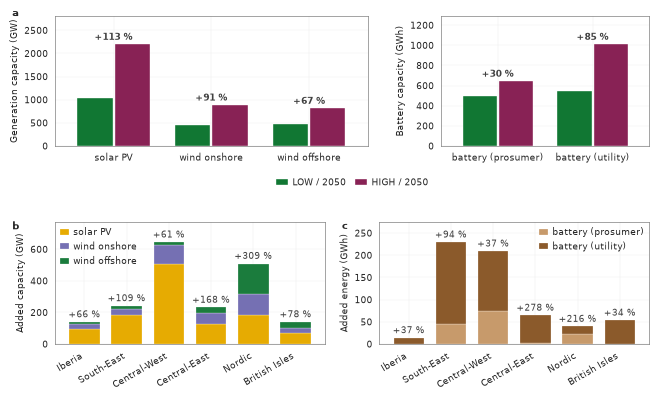

In [9]:
# -- S12: what HIGH/2050 adds over LOW/2050, in total and by zone -------------------------
def figure_s18():
    fig = plt.figure(figsize=(WIDTH, 100 * MM))
    grid = fig.add_gridspec(2, 2, height_ratios=[1.0, 0.94], hspace=0.60, wspace=0.20)
    # a is TWO axes under one letter: generation is power capacity (GW) and batteries are energy
    # capacity (GWh), so one shared axis labelled "GW / GWh" put two units on one scale.
    top = grid[0, :].subgridspec(1, 2, width_ratios=[len(GENERATION_TECHS), len(BATTERY_TECHS)],
                                 wspace=0.28)
    ax_a, ax_a2 = fig.add_subplot(top[0, 0]), fig.add_subplot(top[0, 1])
    ax_b, ax_c = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

    # a -- the two build-outs side by side. LINEAR: the five technologies span 462 to 2196, barely
    # a factor of five, so the smallest bar is still a fifth of the tallest and legible. A log axis
    # was tried and rejected -- it buys nothing over that range and its minor-tick labels
    # (6x10^2, 2x10^3, ...) are four glyphs each in a panel that has five bar pairs to label.
    for ax, techs, ylabel in ((ax_a, GENERATION_TECHS, "Generation capacity (GW)"),
                              (ax_a2, BATTERY_TECHS, "Battery capacity (GWh)")):
        totals = scenario_totals.loc[techs]
        positions = np.arange(len(techs))
        for k, column in enumerate(scenario_totals.columns[:2]):
            ax.bar(positions + (k - 0.5) * 0.38, totals[column].values, 0.36,
                   color=SCENARIO_COLORS[k], edgecolor="white", lw=0.3, label=column, zorder=2)
        for i, name in enumerate(techs):
            ax.annotate(f"+{totals.loc[name, 'change %']:.0f} %",
                        xy=(i, max(totals.loc[name, scenario_totals.columns[:2]])),
                        xytext=(0, 2), textcoords="offset points", ha="center", va="bottom",
                        fontsize=FS["tick"], fontweight="bold", color="0.25")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.22)
        ax.set_xticks(positions)
        ax.set_xticklabels(techs, fontsize=FS["tick"])
        ax.set_xlim(-0.6, len(techs) - 0.4)
        ax.set_ylabel(ylabel, fontsize=FS["label"])
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(True, axis="y", color="0.93", lw=0.3)
        ax.set_axisbelow(True)

    # b and c -- where the extra build-out lands. ADDED capacity, not the HIGH level and not the
    # percentage: a zone that doubles from a small base and one that grows by a third from a large
    # one look identical in percent, and it is the absolute GW that has to meet the deficit.
    # Generation and storage stay in separate panels for the same reason a and b of S11 do: GW and
    # GWh do not stack.
    ZONE_TICKS = [ZONE_LABELS[z] for z in ZONE_ORDER]
    # Short y-labels. "Energy capacity HIGH adds (GWh)" set at 6.5 pt and rotated is 43 mm tall in
    # a 40 mm panel, so it ran past the top of the axes and collided with the panel letter. What
    # the quantity is the difference OF is the caption's job.
    for ax, techs, ylabel in ((ax_b, GENERATION_TECHS, "Added capacity (GW)"),
                              (ax_c, BATTERY_TECHS, "Added energy (GWh)")):
        frame = zonal_added[techs].loc[ZONE_ORDER]
        bottoms = np.zeros(len(frame))
        for column in frame.columns:
            ax.bar(range(len(frame)), frame[column].values, bottom=bottoms, width=0.72,
                   color=TECH_COLORS[column], edgecolor="white", lw=0.2, label=column, zorder=2)
            bottoms += frame[column].values
        # The percentage the zone grows by, over the bar it belongs to: the level is the bar, the
        # ambition is the label, and neither has to be read off the other panel.
        totals_low = zonal_low[techs].loc[ZONE_ORDER].sum(axis=1)
        for i, zone in enumerate(ZONE_ORDER):
            ax.annotate(f"+{bottoms[i] / totals_low.loc[zone] * 100:.0f} %",
                        xy=(i, bottoms[i]), xytext=(0, 2), textcoords="offset points",
                        ha="center", va="bottom", fontsize=FS["tick"], color="0.25")
        ax.set_ylim(0, bottoms.max() * 1.20)
        ax.set_xticks(range(len(frame)))
        ax.set_xticklabels(ZONE_TICKS, fontsize=FS["tick"], rotation=30, ha="right")
        ax.set_xlim(-0.7, len(frame) - 0.3)
        ax.set_ylabel(ylabel, fontsize=FS["label"])
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(True, axis="y", color="0.93", lw=0.3)
        ax.set_axisbelow(True)
        # The free corner differs: b's tallest bars are right of centre (Nordic "+399 %" sat under
        # an upper-right key), c's are left of centre.
        ax.legend(fontsize=FS["tick"], frameon=False, handlelength=1.0,
                  loc="upper left" if ax.get_subplotspec().colspan.start == 0 else "upper right",
                  handletextpad=0.5, borderaxespad=0.2)

    fit_width(fig)
    # One key for both halves of a, centred under them: the same two colours on both axes.
    legend_below(fig, [ax_a, ax_a2], *ax_a.get_legend_handles_labels(), ncol=2)
    panel_letters(fig, [("a", ax_a), ("b", ax_b), ("c", ax_c)])

    # b and c are a, disaggregated: the zonal additions must sum to the Europe-wide difference.
    for _name in GENERATION_TECHS + BATTERY_TECHS:
        _europe = (scenario_totals.loc[_name].iloc[1] - scenario_totals.loc[_name].iloc[0])
        assert np.isclose(_europe, zonal_added[_name].sum()), \
            f"{_name}: the zonal additions do not sum to the Europe-wide difference"
    return fig


with publication_rc():
    fig = figure_s18()
    save(fig, "S18_tyndp_low_vs_high", FIGS)
plt.show()


## 3 · S19: the demand the build-out serves

> **Supplementary Figure 19 | Baseload demand under the DE/2050 scenario.** The typical-year demand
> per balancing zone, smoothed with a one-week centred mean so the seasonal shape is legible at this
> width. This is the demand every residual load in the paper is computed against; it carries no
> climate signal of its own, being a fixed scenario profile.

  S19_baseload_de_2050         179.9 x  65.1 mm   panel 48.6 mm   pdf 52 kB  png 217 kB


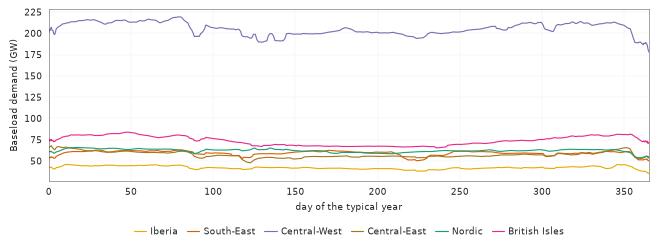

In [11]:
def figure_s19():
    """The demand the build-out has to serve, as a typical year per zone.

    Split out of the capacity figure: it answers a different question (what has to be met, not what
    is installed), it is the only panel there with time on the x axis, and together they were a
    150 mm figure whose caption could then be no longer than 300 words.
    """
    fig, ax = plt.subplots(figsize=(WIDTH, 52 * MM))
    countries_in = {str(c) for c in baseload["country"].values}
    days = np.arange(baseload.sizes["hour_of_year"]) / 24
    for zone in ZONE_ORDER:
        members = [c for c in REALTIME_BALANCING_ZONES[zone] if c in countries_in]
        if not members:
            continue
        total = baseload.sel(country=members).sum("country")
        # A one-week centred mean: the raw hourly series is a black band at this width, and the
        # question here is the seasonal shape, not the diurnal cycle.
        smooth = pd.Series(total.values).rolling(24 * 7, center=True, min_periods=1).mean()
        ax.plot(days, smooth.values, lw=0.9, color=ZONE_COLORS[zone], label=ZONE_LABELS[zone])
    ax.set_xlabel("day of the typical year", fontsize=FS["label"])
    ax.set_ylabel("Baseload demand (GW)", fontsize=FS["label"])
    ax.set_xlim(0, 365)
    ax.grid(color="0.93", lw=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=FS["tick"])
    fit_width(fig)
    handles, labels = ax.get_legend_handles_labels()
    legend_below(fig, ax, handles, labels, ncol=6)
    return fig


with publication_rc():
    fig = figure_s19()
    save(fig, "S19_baseload_de_2050", FIGS)
plt.show()

## 4 · S20 and S21: reservoir operation

The reservoir fleet is the one asset in the system with memory: what it dispatches in August depends
on what it stored in May. Dispatch and storage are therefore shown separately — the first is the
decision, the second the state that constrains it.

> **Supplementary Figure 20 | Reservoir dispatch over the year.** Ensemble-median daily dispatch per
> country at each warming level, over each chain's own 20-year window. Countries with no reservoir
> fleet are omitted rather than drawn as zero.

> **Supplementary Figure 21 | Reservoir storage over the year.** The stored energy behind the
> dispatch in Supplementary Fig. S20, on the same countries and levels.

In [13]:
# ── Country-level components for the reservoir fleet (zonal would hide Norway) ──────────
started = time.perf_counter()
_COMPONENT_FILES = {m: PATH_RESIDUAL_LOAD / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG / "components.nc"
                    for m in models}
COUNTRY_NAMES = {"AT": "Austria", "BG": "Bulgaria", "CH": "Switzerland", "ES": "Spain",
                 "FR": "France", "IT": "Italy", "NO": "Norway", "PT": "Portugal",
                 "RO": "Romania", "SE": "Sweden"}
MONTH_STARTS = [0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334]
MONTH_LABELS = list("JFMAMJJASOND")


def operation_curves(components, variable, dim, keys, mode, smooth_days=7):
    """{key: {period: (n_chain_years, 365)}} — the day-of-year curves each panel is drawn from."""
    return {k: {p: compute_annual_operation_curves(components, period_defs, p, variable, {dim: k},
                                                   mode=mode, smooth_days=smooth_days)
                for p in period_names}
            for k in keys}


def operation_figure(curves, *, mode, ncols, ylabel, height_mm, spread=(10, 90)):
    """One panel per country or zone, one colour per warming level, one legend below the block."""
    labels = list(curves)
    nrows = int(np.ceil(len(labels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(WIDTH, height_mm * MM), squeeze=False,
                             sharex=True, gridspec_kw={"hspace": 0.42, "wspace": 0.48})
    day = np.arange(365)

    for index, label in enumerate(labels):
        ax = axes[index // ncols, index % ncols]
        for period in period_names:
            block = curves[label].get(period)
            if block is None or not len(block):
                continue
            colour = STYLE.gwl_colors[period]
            if mode == "spaghetti":
                # 180 chain-years x 3 levels x 10 panels is 5400 polylines of 365 points. Written
                # as vectors that is a ~100 MB PDF for texture no reader traces line by line, so
                # the thin lines are rasterised at the figure dpi. Everything that carries a
                # number (the mean, the axes, the type) stays vector.
                spaghetti = LineCollection([np.column_stack([day, curve]) for curve in block],
                                           colors=colour, linewidths=0.2, alpha=0.05, zorder=1)
                spaghetti.set_rasterized(True)
                ax.add_collection(spaghetti, autolim=True)
                ax.plot(day, block.mean(axis=0), color=colour, lw=1.0, zorder=3, label=period)
            else:
                low, median, high = np.percentile(block, [spread[0], 50, spread[1]], axis=0)
                ax.fill_between(day, low, high, color=colour, alpha=0.18, lw=0, zorder=1)
                ax.plot(day, median, color=colour, lw=0.9, zorder=3, label=period)

        ax.set_title(COUNTRY_NAMES.get(label, label), fontsize=FS["title"], fontweight="bold")
        ax.set_xlim(0, 364)
        # Quarters labelled, every month ticked: twelve single letters at 7 pt read as unevenly
        # spaced ("J FMAM J J ASOND") because M is twice as wide as J.
        ax.set_xticks(MONTH_STARTS, minor=True)
        ax.set_xticks([MONTH_STARTS[m] for m in (0, 3, 6, 9)])
        ax.set_xticklabels(["Jan", "Apr", "Jul", "Oct"], fontsize=FS["tick"], ha="left")
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(color="0.93", lw=0.3)
        ax.set_axisbelow(True)
        ax.autoscale_view()          # a LineCollection does not update the y limits on its own
        if index % ncols == 0:
            ax.set_ylabel(ylabel, fontsize=FS["label"])

    used = [axes[i // ncols, i % ncols] for i in range(len(labels))]
    for index in range(len(labels), nrows * ncols):
        axes[index // ncols, index % ncols].set_axis_off()

    fit_width(fig)
    legend_below(fig, [a for a in used if a in list(axes[-1])], *gwl_handles(STYLE), ncol=3, title=GWL_TITLE)
    return fig


def _reservoir_curves():
    country_components = {m: xr.open_dataset(path) for m, path in _COMPONENT_FILES.items()}
    probe = country_components[models[0]]
    countries = [str(c) for c in probe["country"].values
                 if float(probe["reservoir_dispatch_gwh"].sel(country=c).sum()) > 0]
    storage = operation_curves(country_components, "reservoir_storage_gwh", "country",
                               countries, mode="mean", smooth_days=1)
    dispatch = operation_curves(country_components, "reservoir_dispatch_gwh", "country",
                                countries, mode="sum")
    return countries, storage, dispatch


# Cached on disk (cordex2energy_analysis.figure_cache), keyed on the input files, the windows and
# the analysis code: the curves are day-of-year reductions of every chain-year, ~2 min per build.
RESERVOIR_COUNTRIES, storage, dispatch = cached(
    "note2_reservoir_curves", _reservoir_curves,
    key=dict(run_tag=RUN_TAG, models=models, periods=period_defs), files=_COMPONENT_FILES.values())
assert set(RESERVOIR_COUNTRIES) <= set(COUNTRY_NAMES), \
    f"unnamed reservoir country: {sorted(set(RESERVOIR_COUNTRIES) - set(COUNTRY_NAMES))}"
print(f"{len(RESERVOIR_COUNTRIES)} countries with a reservoir fleet: "
      f"{', '.join(RESERVOIR_COUNTRIES)}")
print(f"reservoir curves built [{time.perf_counter() - started:.0f}s]")

[cache] hit   note2_reservoir_curves  (32 MB, 0s)
10 countries with a reservoir fleet: AT, BG, CH, ES, FR, IT, NO, PT, RO, SE
reservoir curves built [0s]


  S21_reservoir_storage        179.8 x  98.5 mm   panel 32.1 mm   pdf 2531 kB  png 2150 kB
  S20_reservoir_dispatch       179.9 x  98.9 mm   panel 32.3 mm   pdf 261 kB  png 751 kB


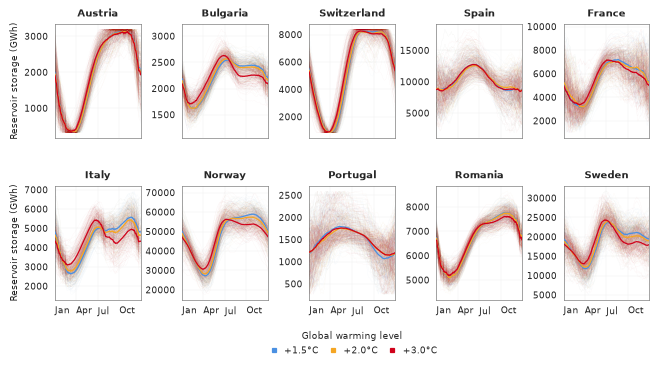

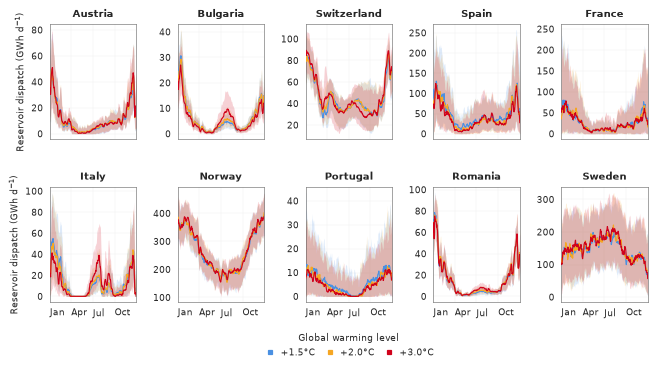

In [14]:
with publication_rc():
    fig = operation_figure(storage, mode="spaghetti", ncols=5,
                           ylabel="Reservoir storage (GWh)", height_mm=84)
    save(fig, "S21_reservoir_storage", FIGS)
plt.show()

with publication_rc():
    fig = operation_figure(dispatch, mode="band", ncols=5,
                           ylabel="Reservoir dispatch (GWh d$^{-1}$)", height_mm=84)
    save(fig, "S20_reservoir_dispatch", FIGS)
plt.show()

## 5 · S22: battery operation

> **Supplementary Figure 22 | Battery throughput by zone.** Energy cycled through the battery fleet
> per zone and warming level, over each chain's own 20-year window. Batteries have no seasonal
> memory — they cycle daily — so throughput rather than a stored-energy curve is what characterises
> them.

  S22_battery_throughput       179.9 x  92.1 mm   panel 29.5 mm   pdf 185 kB  png 601 kB
Battery throughput (GWh cycled/day, median over chain-years, at +1.5°C):
  Iberia         winter    39.2   summer    38.7   summer/winter  0.99x
  South-East     winter   123.4   summer   185.1   summer/winter  1.50x
  Central-West   winter   279.2   summer   513.3   summer/winter  1.84x
  Central-East   winter     8.7   summer    16.9   summer/winter  1.95x
  Nordic         winter     9.4   summer     8.2   summer/winter  0.87x
  British Isles  winter    87.7   summer    59.5   summer/winter  0.68x


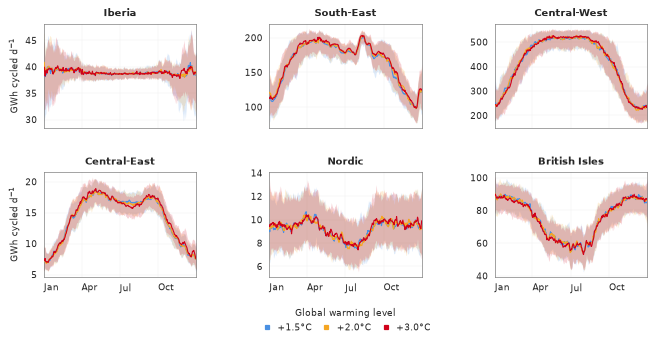

In [16]:
# ── Zonal battery throughput ────────────────────────────────────────────────────────────
zonal_components = {
    m: xr.open_dataset(PATH_RESIDUAL_LOAD / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG
                       / "components_zonal.nc")
    for m in models
}
throughput = operation_curves(zonal_components, "battery_dispatch_gwh", "zone", ZONE_ORDER,
                              mode="throughput")
battery_panels = {ZONE_LABELS[z]: throughput[z] for z in ZONE_ORDER}

with publication_rc():
    fig = operation_figure(battery_panels, mode="band", ncols=3,
                           ylabel="GWh cycled d$^{-1}$", height_mm=76)
    save(fig, "S22_battery_throughput", FIGS)
plt.show()

winter_days = [d for d in range(365) if d < 59 or d >= 334]
print("Battery throughput (GWh cycled/day, median over chain-years, at "
      f"{REFERENCE}):")
for zone in ZONE_ORDER:
    block = throughput[zone][REFERENCE]
    djf, jja = np.median(block[:, winter_days]), np.median(block[:, 151:243])
    print(f"  {ZONE_LABELS[zone]:<14} winter {djf:7.1f}   summer {jja:7.1f}   "
          f"summer/winter {jja / max(djf, 1e-9):5.2f}x")